# Caso: Bodega Doña Rosa
## Taller práctico · Semana 14, sesión B · Grupo 2
**Curso:** Innovación y Transformación Digital · UTP · Sección 35036

**Grupo del proyecto:**

| Integrante | Código estudiantil |
|---|---|
| Coveñas Quispe, Tamara Alison | U23204737 |
| Baylón Vila, Omara Yamileth | U23231338 |
| Paredes Paredes, César Augusto Daniel | U23259768 |
| Yman Avila, Pablo Enrique | U23251279 |

**El taller pide parejas:** confirmar qué dos integrantes presentan este enlace, o la
autorización del docente si participa el grupo completo. Códigos proporcionados por la usuaria.
La fecha/hora técnica real de ejecución se muestra en el Paso 0; no acredita una sesión humana.

**Objetivo:** ejecutar SVM, KNN, árbol y AdaBoost sobre la misma base y priorizar hasta
diez llamadas. El CSV exacto de 160 clientes está incrustado: no requiere Drive,
archivos externos, credenciales ni datos del proyecto.

**Etiqueta del taller:** `moroso=1` significa más de siete días de retraso, no pérdida
definitiva. Los 40 clientes de prueba representan la semana ficticia del ejercicio;
no son una cartera nueva ni clientes de Cervecería Baylón.

**Límite metodológico:** el taller consulta repetidamente prueba para comparar k,
rondas y umbrales. Se conserva ese procedimiento para resolver la consigna, pero sus
resultados son exploratorios, no una evaluación final independiente tras seleccionar.
En APF3 ajustaremos dentro de entrenamiento y reservaremos un test final sin consultar.

**Uso de IA:** preparación asistida por OpenCode; ejecución técnica comprobada.
Cada participante debe revisar, explicar y validar las respuestas antes de entregarlas.
No se afirma que esa revisión humana ya haya ocurrido.


## Paso 0 · Entorno de trabajo

In [1]:
# Dependencias fijadas para reproducir las tablas y respuestas de esta entrega.
# Ejecutar en un entorno nuevo de Colab (Python 3.11–3.13; verificado en 3.12).
import sys
import subprocess
from importlib.metadata import version, PackageNotFoundError

requisitos = {
    "scikit-learn": "1.8.0", "pandas": "2.2.3",
    "numpy": "2.3.5", "matplotlib": "3.10.8",
}
assert (3, 11) <= sys.version_info[:2] < (3, 14), "Usar Python 3.11–3.13, preferiblemente 3.12."
instalar = []
for paquete, requerido in requisitos.items():
    try:
        actual = version(paquete)
    except PackageNotFoundError:
        actual = None
    if actual != requerido:
        instalar.append(f"{paquete}=={requerido}")
if instalar:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *instalar])
print("Dependencias listas:", requisitos)


Dependencias listas: {'scikit-learn': '1.8.0', 'pandas': '2.2.3', 'numpy': '2.3.5', 'matplotlib': '3.10.8'}


In [2]:
import io
import sys
import sklearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
print("Python:", sys.version.split()[0])
print("sklearn:", sklearn.__version__, "| pandas:", pd.__version__, "| numpy:", np.__version__)
from datetime import datetime, timezone
print("Ejecución técnica UTC:", datetime.now(timezone.utc).isoformat())
for paquete, requerido in requisitos.items():
    assert version(paquete) == requerido
assert sklearn.__version__ == requisitos["scikit-learn"]
assert np.__version__ == requisitos["numpy"] and pd.__version__ == requisitos["pandas"]


Python: 3.12.14
sklearn: 1.8.0 | pandas: 2.2.3 | numpy: 2.3.5
Ejecución técnica UTC: 2026-11-12T21:39:23.730548+00:00


### Registra
Se fijan scikit-learn 1.8.0, pandas 2.2.3, NumPy 2.3.5 y Matplotlib 3.10.8.
La salida anterior registra Python y la fecha técnica de ejecución. La primera celda
instala solo lo que falta antes de importar las bibliotecas. Si ya se habían importado
versiones distintas, reiniciar la sesión de Colab y ejecutar desde el principio.
Las respuestas numéricas corresponden a este entorno; no se copian las referencias
del PDF para sustituir una ejecución distinta.


## Paso 1 · Carga y exploración de la base

In [3]:
datos = """cliente,monto_fiado,compras_mes,dias_sin_comprar,fiados_previos,pagos_puntuales,dias_prom_pago,deuda_vencida,antiguedad_meses,moroso
C001,255.6,18,27,30,15,11,8.0,52,0
C002,251.5,11,35,8,4,17,23.9,11,1
C003,127.3,5,0,2,2,12,4.7,2,0
C004,217.8,9,43,20,13,9,35.2,39,0
C005,165.0,3,39,1,1,14,0.8,22,0
C006,229.3,5,45,15,10,17,137.3,29,1
C007,108.3,10,12,2,2,7,0.0,5,0
C008,152.7,16,22,2,1,6,37.0,23,0
C009,270.0,5,25,11,9,17,105.4,39,1
C010,248.7,7,6,0,0,14,2.6,22,0
C011,106.8,0,16,26,17,15,53.5,50,0
C012,266.9,0,1,18,15,9,42.3,48,0
C013,131.6,11,5,28,13,20,86.1,43,1
C014,211.1,20,22,15,12,26,73.2,55,1
C015,219.2,12,14,17,7,17,102.1,44,1
C016,132.5,0,3,13,8,17,94.4,11,1
C017,251.6,12,38,14,9,10,51.0,52,0
C018,150.3,2,5,17,12,9,18.4,40,0
C019,289.0,14,10,7,4,19,1.7,6,0
C020,282.3,9,10,21,17,19,4.0,18,0
C021,272.1,7,23,9,4,15,113.9,10,1
C022,274.3,4,45,28,23,8,10.7,59,0
C023,61.2,3,1,5,2,13,119.9,44,1
C024,201.5,7,7,5,4,9,14.1,56,0
C025,227.5,9,15,7,5,11,0.5,17,0
C026,168.1,11,5,29,24,6,12.6,39,0
C027,168.2,14,0,7,6,8,22.2,37,0
C028,76.4,20,42,24,18,15,1.6,46,0
C029,65.0,0,10,9,8,10,27.7,8,0
C030,239.3,19,28,19,12,12,95.5,31,1
C031,61.9,11,40,2,2,6,25.7,39,0
C032,223.9,1,34,20,13,17,36.6,50,1
C033,41.6,18,1,2,1,12,149.6,40,0
C034,135.4,17,16,16,9,12,7.0,27,0
C035,26.7,6,2,24,13,17,44.4,28,0
C036,204.9,3,42,25,7,21,146.3,21,1
C037,102.0,6,21,12,6,15,36.9,10,0
C038,151.0,17,44,7,5,14,52.5,17,0
C039,100.2,19,18,10,8,8,44.8,9,0
C040,164.4,6,25,16,14,7,2.0,14,0
C041,204.1,9,2,22,11,13,76.9,52,0
C042,66.7,15,45,25,16,4,124.8,32,0
C043,237.6,3,39,7,3,16,128.8,6,1
C044,239.1,15,23,4,3,12,51.6,26,0
C045,283.8,4,10,20,15,11,18.6,17,0
C046,126.6,17,20,19,10,14,68.4,40,0
C047,264.5,2,20,4,3,16,133.8,50,1
C048,46.2,20,36,1,1,18,143.5,1,1
C049,298.3,15,13,4,2,19,12.0,28,0
C050,79.4,5,29,23,13,17,131.3,27,1
C051,124.7,16,37,10,3,20,80.0,60,1
C052,46.2,13,9,2,2,12,114.0,22,0
C053,253.8,9,35,8,4,14,4.2,10,0
C054,156.1,15,23,14,10,16,143.0,12,1
C055,289.5,14,9,18,11,13,85.2,29,0
C056,60.5,1,0,26,25,2,4.2,36,0
C057,269.7,4,40,11,7,8,43.8,20,0
C058,120.7,13,40,19,10,14,1.9,27,1
C059,86.2,8,2,29,18,14,78.8,40,0
C060,204.0,6,24,9,5,13,53.1,18,0
C061,28.5,11,4,0,0,9,50.2,58,0
C062,167.1,3,2,15,9,16,107.7,13,0
C063,152.6,20,2,18,12,16,88.9,57,0
C064,33.6,11,43,10,6,19,1.3,53,0
C065,141.6,0,23,17,6,16,87.1,58,1
C066,105.4,9,45,20,15,11,44.0,48,0
C067,89.6,15,35,25,21,11,5.3,32,0
C068,280.5,12,33,3,2,16,18.1,37,0
C069,187.5,10,4,14,8,23,38.9,13,1
C070,63.2,13,19,8,6,16,110.6,21,1
C071,232.0,0,25,10,8,8,116.7,28,1
C072,123.5,10,27,1,1,12,1.6,57,0
C073,187.7,8,6,13,5,10,29.3,48,0
C074,126.4,19,0,2,1,14,106.7,34,0
C075,198.8,12,28,28,25,19,54.4,36,0
C076,210.9,3,4,17,11,14,109.7,26,0
C077,99.4,17,43,13,9,10,53.5,26,0
C078,252.7,6,15,7,5,16,7.5,55,1
C079,193.1,20,42,1,1,12,37.9,1,0
C080,189.5,7,18,15,8,9,39.8,20,0
C081,81.0,17,19,30,17,16,119.9,25,0
C082,91.1,16,34,20,16,5,19.0,42,0
C083,130.7,15,41,30,23,8,8.3,25,0
C084,29.5,13,7,22,9,17,84.1,19,0
C085,35.3,0,20,6,4,2,26.4,5,0
C086,205.6,4,5,11,8,15,35.2,16,0
C087,108.6,18,32,8,1,21,143.1,7,1
C088,221.7,15,32,9,4,18,68.3,43,1
C089,41.0,9,6,26,5,16,67.7,26,0
C090,227.2,16,40,9,6,17,130.8,14,1
C091,80.0,13,45,2,1,10,77.0,33,0
C092,263.5,16,40,3,2,12,136.7,30,1
C093,273.8,11,36,14,11,13,60.2,29,1
C094,213.0,1,34,20,18,11,51.8,35,0
C095,130.4,8,12,8,4,13,12.1,38,0
C096,27.2,4,45,14,10,17,8.0,12,0
C097,233.1,18,14,7,5,11,42.4,10,0
C098,177.6,18,24,14,13,11,0.5,44,0
C099,43.0,4,32,10,5,14,4.2,59,0
C100,179.8,18,35,17,10,15,75.3,33,0
C101,21.7,6,14,5,4,14,69.2,28,0
C102,146.4,4,19,29,26,3,0.1,38,0
C103,191.7,5,21,3,2,10,4.0,3,0
C104,244.7,11,16,21,19,16,57.3,23,1
C105,101.4,5,15,16,12,11,24.9,22,0
C106,85.0,5,41,23,11,17,52.0,26,1
C107,112.7,14,11,14,9,14,2.5,45,0
C108,36.6,8,19,27,11,5,111.6,30,0
C109,280.8,14,6,2,1,8,10.1,52,0
C110,266.6,0,34,6,4,9,21.0,29,0
C111,188.6,2,37,3,1,11,30.3,3,1
C112,40.9,5,22,20,12,12,52.7,41,0
C113,43.4,7,2,21,13,15,144.2,48,0
C114,281.0,5,5,22,15,8,6.6,35,0
C115,55.0,8,11,29,23,8,4.0,57,0
C116,60.8,19,5,26,16,4,3.2,25,0
C117,239.9,9,10,28,19,22,90.0,48,1
C118,104.4,12,23,1,1,16,21.9,1,0
C119,135.2,16,26,3,1,22,128.9,3,1
C120,134.8,3,32,21,18,10,0.7,48,0
C121,216.0,3,42,18,13,9,42.4,53,0
C122,152.3,8,34,18,9,25,86.0,32,1
C123,247.4,13,21,16,11,9,38.6,46,0
C124,158.9,10,15,12,6,19,24.8,20,1
C125,101.3,2,40,4,3,16,98.8,44,0
C126,74.5,13,0,3,3,7,38.9,30,0
C127,231.4,19,33,0,0,15,123.3,19,1
C128,81.5,11,24,7,5,10,8.5,6,0
C129,190.5,18,22,11,7,11,53.7,11,1
C130,188.4,8,8,29,21,7,60.4,55,0
C131,289.7,8,13,7,4,17,123.4,27,1
C132,45.1,6,14,6,4,7,1.3,60,0
C133,78.1,10,1,1,1,18,97.4,22,0
C134,205.2,12,26,3,2,13,70.1,4,1
C135,112.7,2,26,19,12,16,111.1,16,1
C136,56.0,20,18,11,10,12,55.6,22,0
C137,270.7,3,41,19,16,10,30.9,43,0
C138,224.8,11,21,3,2,15,95.1,44,1
C139,82.3,6,3,23,22,10,12.1,45,0
C140,46.7,18,2,8,4,22,0.5,19,0
C141,255.9,13,16,1,1,9,84.4,23,0
C142,179.6,0,8,28,20,11,99.0,35,0
C143,280.3,0,39,11,4,15,103.0,37,1
C144,164.8,4,38,9,7,6,30.1,25,0
C145,84.6,17,44,1,0,10,80.5,12,0
C146,57.4,18,23,18,8,9,76.4,47,0
C147,137.0,11,22,8,3,14,12.5,32,1
C148,211.5,11,40,7,3,14,87.9,58,1
C149,21.2,13,29,20,17,15,139.4,57,0
C150,130.7,10,39,20,18,4,18.6,54,0
C151,133.1,10,8,4,2,9,11.2,58,0
C152,207.9,7,8,3,2,16,51.1,38,0
C153,74.6,10,2,7,4,18,115.6,18,1
C154,265.3,6,18,12,9,6,55.5,10,0
C155,111.0,15,36,8,6,18,141.1,7,1
C156,251.5,14,24,13,9,13,127.7,57,0
C157,251.7,15,25,3,2,10,75.8,17,0
C158,267.8,7,4,2,1,17,75.0,2,1
C159,92.5,8,5,3,2,14,4.8,3,0
C160,255.2,9,3,21,17,2,17.4,18,0
"""
df = pd.read_csv(io.StringIO(datos))
assert df.shape == (160, 10)
assert df["cliente"].is_unique
assert df["moroso"].isin([0, 1]).all()
assert (df["pagos_puntuales"] <= df["fiados_previos"]).all()
display(df.head())
assert not df.isna().any().any()
assert df["moroso"].value_counts().to_dict() == {0: 112, 1: 48}
limites = {
    "monto_fiado": (20, 300), "compras_mes": (0, 20),
    "dias_sin_comprar": (0, 45), "fiados_previos": (0, 30),
    "pagos_puntuales": (0, 30), "dias_prom_pago": (2, 30),
    "deuda_vencida": (0, 150), "antiguedad_meses": (1, 60),
}
for columna, (minimo, maximo) in limites.items():
    assert df[columna].between(minimo, maximo).all(), columna
print("Validaciones: 160 IDs únicos, sin nulos, clases 112/48 y rangos correctos.")


,cliente,monto_fiado,compras_mes,dias_sin_comprar,fiados_previos,pagos_puntuales,dias_prom_pago,deuda_vencida,antiguedad_meses,moroso
0,C001,255.6,18,27,30,15,11,8.0,52,0
1,C002,251.5,11,35,8,4,17,23.9,11,1
2,C003,127.3,5,0,2,2,12,4.7,2,0
3,C004,217.8,9,43,20,13,9,35.2,39,0
4,C005,165.0,3,39,1,1,14,0.8,22,0


Validaciones: 160 IDs únicos, sin nulos, clases 112/48 y rangos correctos.


Filas y columnas: (160, 10)
Valores nulos por columna:
 cliente             0
monto_fiado         0
compras_mes         0
dias_sin_comprar    0
fiados_previos      0
pagos_puntuales     0
dias_prom_pago      0
deuda_vencida       0
antiguedad_meses    0
moroso              0
dtype: int64
Clientes por clase:
 moroso
0    112
1     48
Name: count, dtype: int64
Porcentaje de morosos: 30.0


,monto_fiado,compras_mes,dias_sin_comprar,fiados_previos,pagos_puntuales,dias_prom_pago,deuda_vencida,antiguedad_meses,moroso
count,160.0,160.0,160.0,160.0,160.0,160.0,160.0,160.0,160.0
mean,160.0,9.8,21.4,13.0,8.5,12.9,56.5,30.4,0.3
std,80.6,5.8,14.2,8.7,6.5,4.7,45.2,16.8,0.5
min,21.2,0.0,0.0,0.0,0.0,2.0,0.0,1.0,0.0
25%,88.8,5.0,8.0,5.8,3.0,9.8,12.6,17.8,0.0
50%,157.5,10.0,21.0,12.0,7.5,13.0,51.0,29.0,0.0
75%,231.6,15.0,34.2,20.0,13.0,16.0,91.1,44.0,1.0
max,298.3,20.0,45.0,30.0,26.0,26.0,149.6,60.0,1.0


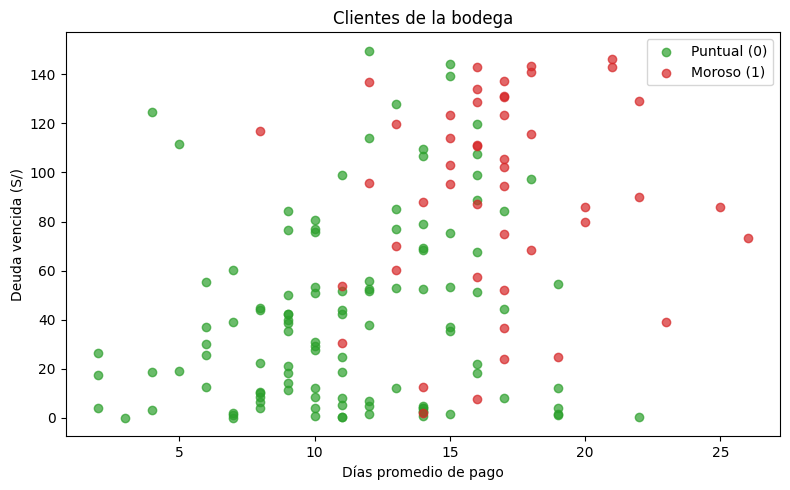

In [4]:
print("Filas y columnas:", df.shape)
print("Valores nulos por columna:\n", df.isnull().sum())
print("Clientes por clase:\n", df["moroso"].value_counts().sort_index())
print("Porcentaje de morosos:", 100 * df["moroso"].mean())
display(df.describe().round(1))
fig, ax = plt.subplots(figsize=(8, 5))
for etiqueta, color, nombre in [(0, "tab:green", "Puntual (0)"), (1, "tab:red", "Moroso (1)")]:
    grupo = df[df.moroso == etiqueta]
    ax.scatter(grupo.dias_prom_pago, grupo.deuda_vencida, c=color, label=nombre, alpha=.7)
ax.set(xlabel="Días promedio de pago", ylabel="Deuda vencida (S/)", title="Clientes de la bodega")
ax.legend()
plt.tight_layout()
plt.show()

### Registra
- **Tamaño y nulos:** 160 filas y 10 columnas, sin valores nulos. Hay un identificador, ocho atributos numéricos y una etiqueta binaria.
- **Distribución:** 48 morosos (30 %) y 112 puntuales (70 %).
- **Patrón visual:** los morosos tienden a concentrarse en mayores días promedio de pago y deudas vencidas elevadas. Existe superposición entre clases: algunos puntuales también tienen deudas altas y algunos morosos tienen deudas bajas. Ninguna de estas variables determina por sí sola la etiqueta. Además, días promedio de pago no equivale a días de retraso; no se debe reconstruir la etiqueta usando directamente ese atributo.

## Paso 2 · Separación y escalado

No incluimos `cliente` como predictor. Se mantienen exactamente las ocho variables
del taller. No se introduce `punctuality_rate` aquí: ese campo corresponde al contrato
de Baylón y se explica en la transferencia del Paso 9.


In [5]:
variables = ["monto_fiado", "compras_mes", "dias_sin_comprar", "fiados_previos",
             "pagos_puntuales", "dias_prom_pago", "deuda_vencida", "antiguedad_meses"]
X = df[variables]
y = df["moroso"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
escalador = StandardScaler()
X_train_esc = escalador.fit_transform(X_train)
X_test_esc = escalador.transform(X_test)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
display(pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Puntuales": [(y_train == 0).sum(), (y_test == 0).sum()],
    "Morosos": [y_train.sum(), y_test.sum()],
    "Morosidad (%)": [100*y_train.mean(), 100*y_test.mean()]}))
assert set(X_train.index).isdisjoint(X_test.index)

Entrenamiento: (120, 8) | Prueba: (40, 8)


,Conjunto,Puntuales,Morosos,Morosidad (%)
0,Entrenamiento,84,36,30.0
1,Prueba,28,12,30.0


### Registra
- **Distribución:** 120 clientes de entrenamiento (84 puntuales y 36 morosos) y 40 de prueba (28 puntuales y 12 morosos).
- **`stratify=y`:** conserva el 30 % de morosos en cada conjunto y permite una comparación representativa de las dos clases.
- **Fuga de datos:** ajustar el escalador con toda la base incorporaría información de prueba en las medias y desviaciones usadas para entrenar. La evaluación dejaría de ser completamente independiente y podría resultar optimista. Por eso usamos `fit_transform` solo en entrenamiento y `transform` en prueba.
- El identificador `cliente` queda fuera del entrenamiento. En una aplicación real, los atributos deben corresponder a información disponible antes del pago que queremos predecir.

## Paso 3 · SVM lineal

In [6]:
svm = SVC(kernel="linear", probability=True, random_state=42)
svm.fit(X_train_esc, y_train)
pred_svm = svm.predict(X_test_esc)
print("Accuracy SVM:", round(accuracy_score(y_test, pred_svm), 3))
print("Recall SVM:", round(recall_score(y_test, pred_svm), 3))

Accuracy SVM: 0.95
Recall SVM: 0.917


### Registra
El SVM obtiene **accuracy = 0.950** y **recall = 0.917**: identifica a 11 de los 12 morosos. Recibe atributos estandarizados porque la escala afecta la geometría del margen y la regularización. Sin escalar, montos de cientos de soles podrían tener un peso desproporcionado frente a variables con rangos menores, aunque no sean más informativos.

## Paso 4 · KNN y reto del número de vecinos

In [7]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_esc, y_train)
pred_knn = knn.predict(X_test_esc)
filas_k = []
for k in [1, 3, 5, 7, 9]:
    modelo_k = KNeighborsClassifier(n_neighbors=k)
    modelo_k.fit(X_train_esc, y_train)
    pred_k = modelo_k.predict(X_test_esc)
    filas_k.append({"k": k, "Accuracy": accuracy_score(y_test, pred_k),
                    "Recall": recall_score(y_test, pred_k, zero_division=0)})
tabla_k = pd.DataFrame(filas_k).set_index("k")
display(tabla_k.round(3))

,Accuracy,Recall
k,,
1,0.875,0.750
3,0.900,0.750
5,0.900,0.750
7,0.900,0.667
9,0.925,0.750


### Registra
| k | Accuracy | Recall |
|---|---:|---:|
| 1 | 0.875 | 0.750 |
| 3 | 0.900 | 0.750 |
| 5 | 0.900 | 0.750 |
| 7 | 0.900 | 0.667 |
| 9 | 0.925 | 0.750 |

El mejor accuracy es **0.925 con k=9**. El recall no aumenta de manera constante: se mantiene en 0.750 salvo en k=7, donde baja a 0.667. Con k=1, una sola observación cercana decide la clase; si ese vecino es atípico o está mal etiquetado, puede cambiar la predicción. Aumentar k suaviza las decisiones, pero también puede favorecer la clase mayoritaria. La comparación principal mantiene k=3, como pide el taller.

## Paso 5 · Árbol de decisión y reglas interpretables

Accuracy Árbol: 0.8
Recall Árbol: 0.917
|--- dias_prom_pago <= 15.50
|   |--- deuda_vencida <= 53.60
|   |   |--- dias_prom_pago <= 13.50
|   |   |   |--- class: 0
|   |   |--- dias_prom_pago >  13.50
|   |   |   |--- class: 0
|   |--- deuda_vencida >  53.60
|   |   |--- monto_fiado <= 189.45
|   |   |   |--- class: 0
|   |   |--- monto_fiado >  189.45
|   |   |   |--- class: 1
|--- dias_prom_pago >  15.50
|   |--- deuda_vencida <= 22.90
|   |   |--- antiguedad_meses <= 54.00
|   |   |   |--- class: 0
|   |   |--- antiguedad_meses >  54.00
|   |   |   |--- class: 1
|   |--- deuda_vencida >  22.90
|   |   |--- dias_prom_pago <= 16.50
|   |   |   |--- class: 1
|   |   |--- dias_prom_pago >  16.50
|   |   |   |--- class: 1



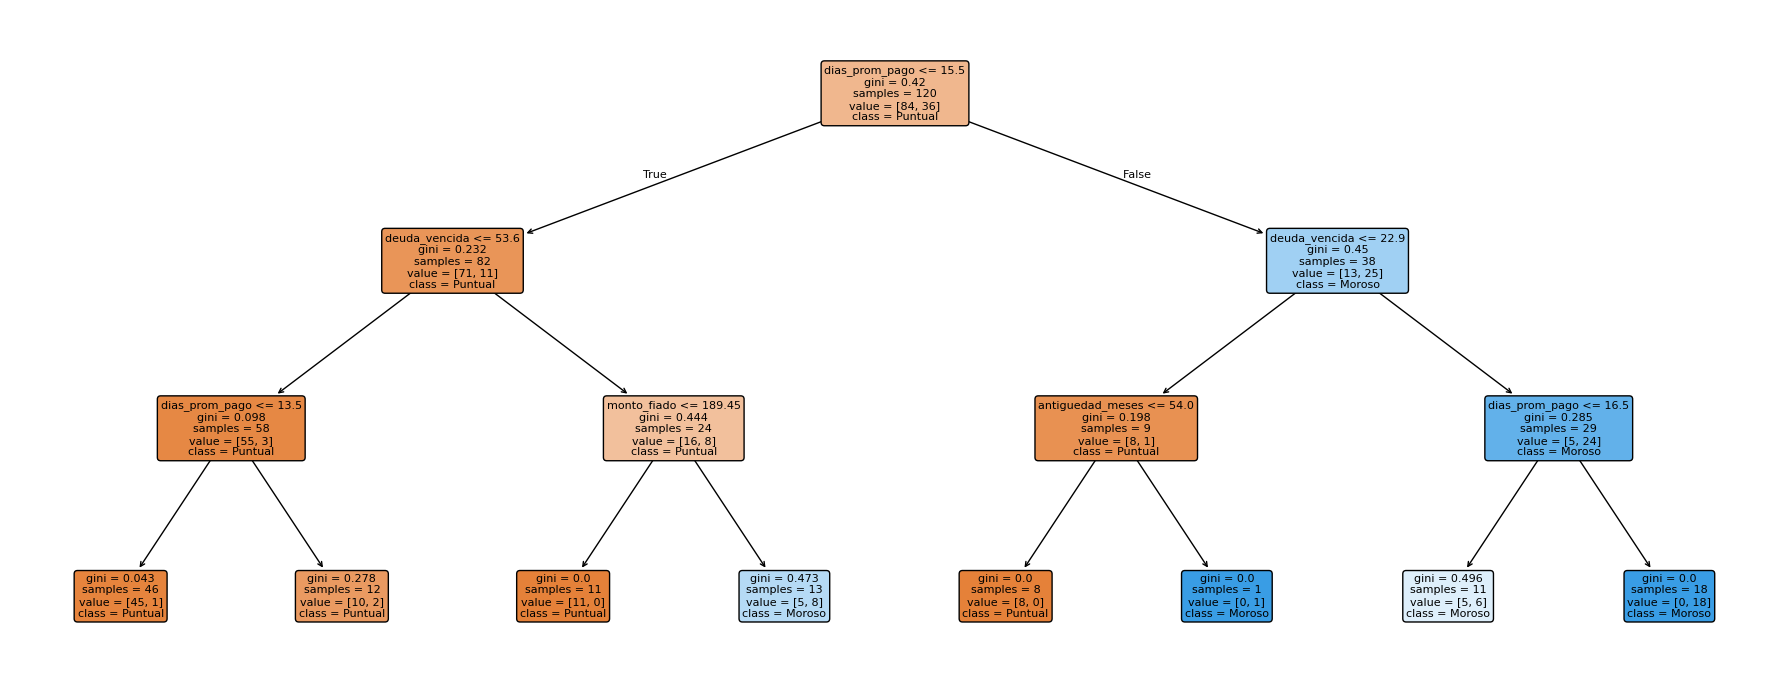

In [8]:
arbol = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol.fit(X_train, y_train)
pred_arbol = arbol.predict(X_test)
print("Accuracy Árbol:", round(accuracy_score(y_test, pred_arbol), 3))
print("Recall Árbol:", round(recall_score(y_test, pred_arbol), 3))
print(export_text(arbol, feature_names=variables))
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arbol, feature_names=variables, class_names=["Puntual", "Moroso"],
          filled=True, rounded=True, fontsize=8, ax=ax)
plt.tight_layout()
plt.show()

### Registra
- **Resultado:** accuracy = 0.800 y recall = 0.917.
- **Regla completa:** si el cliente demora en promedio **más de 15.5 días** en pagar, tiene una deuda vencida **mayor a S/ 22.90** y su promedio de pago es **como máximo 16.5 días**, el árbol lo clasifica como moroso. Esta es una ruta completa de la raíz a una hoja.
- **Rama que podría simplificarse:** bajo `dias_prom_pago > 15.5` y `deuda_vencida > 22.9`, las dos hojas del corte en 16.5 días terminan en clase 1. Se podría eliminar ese último corte sin cambiar las etiquetas predichas. También ocurre con el corte en 13.5 días bajo `dias_prom_pago <= 15.5` y `deuda_vencida <= 53.6`: ambas hojas son clase 0. La simplificación podría cambiar probabilidades por hoja, aunque no la clase final, y debe validarse antes de aplicarla.
- **Modelo para explicar:** mostraríamos el árbol a Doña Rosa, porque permite seguir condiciones claras en soles y días. KNN depende de vecinos y distancias estandarizadas menos fáciles de comunicar. El límite de profundidad es una forma de prepoda; no garantiza eliminar todo sobreajuste.

## Paso 6 · AdaBoost y reto de las rondas

In [9]:
boosting = AdaBoostClassifier(n_estimators=50, random_state=42)
boosting.fit(X_train, y_train)
pred_boost = boosting.predict(X_test)
print("Accuracy Boosting:", round(accuracy_score(y_test, pred_boost), 3))
print("Recall Boosting:", round(recall_score(y_test, pred_boost), 3))
filas_b = []
for rondas in [50, 400]:
    modelo_b = AdaBoostClassifier(n_estimators=rondas, random_state=42)
    modelo_b.fit(X_train, y_train)
    filas_b.append({"Rondas": rondas,
        "Accuracy entrenamiento": accuracy_score(y_train, modelo_b.predict(X_train)),
        "Accuracy prueba": accuracy_score(y_test, modelo_b.predict(X_test))})
tabla_b = pd.DataFrame(filas_b).set_index("Rondas")
display(tabla_b.round(3))

Accuracy Boosting: 0.95
Recall Boosting: 0.917


,Accuracy entrenamiento,Accuracy prueba
Rondas,,
50,0.95,0.950
400,1.00,0.875


### Registra
| Rondas | Accuracy entrenamiento | Accuracy prueba |
|---|---:|---:|
| 50 | 0.950 | 0.950 |
| 400 | 1.000 | 0.875 |

Al pasar de 50 a 400 rondas, el accuracy de entrenamiento sube 5 puntos porcentuales, pero el de prueba baja 7.5 puntos. La brecha entrenamiento-prueba llega a 12.5 puntos: hay evidencia de sobreajuste. El experimento **refuta el mito de que más rondas o mayor complejidad siempre mejoran un modelo**. Para evitarlo en el proyecto, seleccionaríamos número de rondas, profundidad y tasa de aprendizaje mediante validación cruzada dentro del entrenamiento y reservaríamos una prueba final sin usar para ajustar parámetros. Este taller compara sobre prueba por fines didácticos; esa práctica no debe repetirse continuamente en una evaluación real.

## Paso 7 · Comparación de modelos y costo del error

La matriz se calcula para AdaBoost de 50 rondas, el modelo elegido al final; no para
el árbol usado como recurso didáctico de explicabilidad.


,Accuracy,Precisión,Recall,F1
Modelo,,,,
SVM,0.95,0.917,0.917,0.917
KNN (k=3),0.90,0.900,0.750,0.818
Árbol,0.80,0.611,0.917,0.733
Boosting,0.95,0.917,0.917,0.917


Matriz: filas = clase real; columnas = clase predicha; orden = [0, 1]
[[27  1]
 [ 1 11]]
              precision    recall  f1-score   support

 Puntual (0)       0.96      0.96      0.96        28
  Moroso (1)       0.92      0.92      0.92        12

    accuracy                           0.95        40
   macro avg       0.94      0.94      0.94        40
weighted avg       0.95      0.95      0.95        40



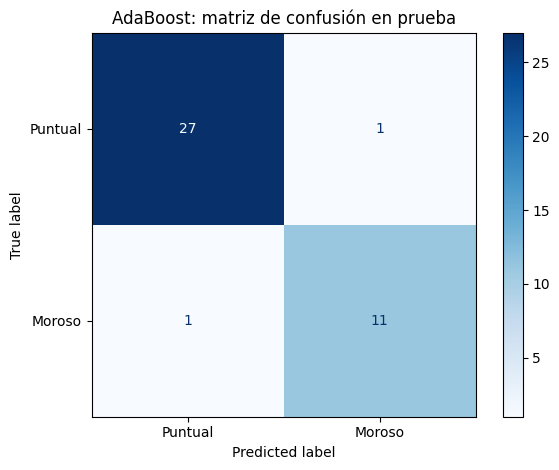

Costo hipotético de falsos negativos: S/ 150


In [10]:
predicciones = {"SVM": pred_svm, "KNN (k=3)": pred_knn,
                "Árbol": pred_arbol, "Boosting": pred_boost}
filas = []
for nombre, pred in predicciones.items():
    filas.append({"Modelo": nombre,
                  "Accuracy": accuracy_score(y_test, pred),
                  "Precisión": precision_score(y_test, pred, zero_division=0),
                  "Recall": recall_score(y_test, pred, zero_division=0),
                  "F1": f1_score(y_test, pred, zero_division=0)})
comparacion = pd.DataFrame(filas).set_index("Modelo")
display(comparacion.round(3))
matriz = confusion_matrix(y_test, pred_boost, labels=[0, 1])
print("Matriz: filas = clase real; columnas = clase predicha; orden = [0, 1]")
print(matriz)
print(classification_report(y_test, pred_boost,
      target_names=["Puntual (0)", "Moroso (1)"], zero_division=0))
ConfusionMatrixDisplay(matriz, display_labels=["Puntual", "Moroso"]).plot(cmap="Blues")
plt.title("AdaBoost: matriz de confusión en prueba")
plt.tight_layout()
plt.show()
vn, fp, fn, vp = matriz.ravel()
print("Costo hipotético de falsos negativos: S/", fn * 150)

### Registra
| Modelo | Accuracy | Precisión | Recall | F1 |
|---|---:|---:|---:|---:|
| SVM | 0.950 | 0.917 | 0.917 | 0.917 |
| KNN (k=3) | 0.900 | 0.900 | 0.750 | 0.818 |
| Árbol | 0.800 | 0.611 | 0.917 | 0.733 |
| Boosting | 0.950 | 0.917 | 0.917 | 0.917 |

**Mayor recall:** SVM, árbol y Boosting empatan con 11/12 = 91.67 %. Nos importa detectar morosos porque un falso negativo deja sin advertencia un fiado en riesgo. Entre esos modelos, SVM y Boosting generan menos falsas alarmas que el árbol.

**Matriz de Boosting:** 27 verdaderos negativos, 1 falso positivo, 1 falso negativo y 11 verdaderos positivos. Dejó pasar **un moroso**. Bajo el supuesto del taller de S/ 150 perdidos por cada falso negativo, el costo potencial sería **S/ 150**. Es un escenario hipotético: pagar tarde no equivale necesariamente a no pagar nunca.

**Limitación del accuracy:** si se predijera siempre “puntual”, se acertaría el 70 % de los casos, pero el recall de morosos sería 0 %. Por ello complementamos accuracy con recall, precisión, F1 y matriz de confusión.

## Paso 8 · Umbrales y prioridad de las diez llamadas

In [11]:
prob_moroso = boosting.predict_proba(X_test)[:, 1]
resultado = X_test.copy()
resultado.insert(0, "cliente", df.loc[X_test.index, "cliente"])
resultado["real"] = y_test  # Solo para evaluar la simulación, no para seleccionar llamadas.
resultado["prob_moroso"] = prob_moroso
# Ordenamos por el valor completo para no introducir empates al redondear.
# El identificador solo deshace empates exactos, no es atributo predictivo.
resultado = resultado.sort_values(["prob_moroso", "cliente"], ascending=[False, True])
top10 = resultado.head(10)
print("De los 10 clientes priorizados, morosos según la etiqueta simulada:", int(top10["real"].sum()))
display(top10.round(3))
filas_u = []
for umbral in [0.3, 0.5, 0.7]:
    pred_u = (prob_moroso >= umbral).astype(int)
    filas_u.append({"Umbral": umbral, "N.º de alertas": int(pred_u.sum()),
                   "Recall": recall_score(y_test, pred_u, zero_division=0),
                   "Precisión": precision_score(y_test, pred_u, zero_division=0)})
tabla_u = pd.DataFrame(filas_u).set_index("Umbral")
display(tabla_u.round(3))
umbral_operativo = 0.5
llamadas = resultado[resultado["prob_moroso"] >= umbral_operativo].head(10)
print("Llamadas asignadas:", len(llamadas))
print("Morosos detectados en las llamadas:", int(llamadas["real"].sum()))
print("Cobertura de morosos por las llamadas:", round(llamadas["real"].sum()/y_test.sum(), 3))
print("Puntaje del décimo puesto:", round(top10.iloc[-1]["prob_moroso"], 6))
assert len(llamadas) <= 10

De los 10 clientes priorizados, morosos según la etiqueta simulada: 9


,cliente,monto_fiado,compras_mes,dias_sin_comprar,fiados_previos,pagos_puntuales,dias_prom_pago,deuda_vencida,antiguedad_meses,real,prob_moroso
35,C036,204.9,3,42,25,7,21,146.3,21,1,0.658
134,C135,112.7,2,26,19,12,16,111.1,16,1,0.646
118,C119,135.2,16,26,3,1,22,128.9,3,1,0.644
74,C075,198.8,12,28,28,25,19,54.4,36,0,0.638
13,C014,211.1,20,22,15,12,26,73.2,55,1,0.615
15,C016,132.5,0,3,13,8,17,94.4,11,1,0.589
20,C021,272.1,7,23,9,4,15,113.9,10,1,0.554
130,C131,289.7,8,13,7,4,17,123.4,27,1,0.540
157,C158,267.8,7,4,2,1,17,75.0,2,1,0.539
116,C117,239.9,9,10,28,19,22,90.0,48,1,0.520


,N.º de alertas,Recall,Precisión
Umbral,,,
0.3,35,1.000,0.343
0.5,12,0.917,0.917
0.7,0,0.000,0.000


Llamadas asignadas: 10
Morosos detectados en las llamadas: 9
Cobertura de morosos por las llamadas: 0.75
Puntaje del décimo puesto: 0.520065


### Registra · Resultados de priorización
| Orden | Cliente | Monto fiado (S/) | Puntaje de morosidad | Clase real |
|---|---|---:|---:|---:|
| 1 | C036 | 204.90 | 0.658 | 1 |
| 2 | C135 | 112.70 | 0.646 | 1 |
| 3 | C119 | 135.20 | 0.644 | 1 |
| 4 | C075 | 198.80 | 0.638 | 0 |
| 5 | C014 | 211.10 | 0.615 | 1 |
| 6 | C016 | 132.50 | 0.589 | 1 |
| 7 | C021 | 272.10 | 0.554 | 1 |
| 8 | C131 | 289.70 | 0.540 | 1 |
| 9 | C158 | 267.80 | 0.539 | 1 |
| 10 | C117 | 239.90 | 0.520 | 1 |

Se priorizaron **9 morosos según la etiqueta simulada de 10 llamadas**, una precisión de selección del **90 %**. Las llamadas cubren 9 de los 12 morosos de prueba, es decir, **75 %**. El 91.67 % de recall del clasificador no es el recall de las diez llamadas: quedan tres morosos fuera de la lista operativa.

| Umbral | Alertas | Recall | Precisión |
|---|---:|---:|---:|
| 0.3 | 35 | 1.000 | 0.343 |
| 0.5 | 12 | 0.917 | 0.917 |
| 0.7 | 0 | 0.000 | 0.000* |

\* Con cero alertas la precisión no está definida; el código presenta 0 por `zero_division=0`.

**Umbral y capacidad.** Elegimos **0.5 como filtro de candidatos**, seguido de orden descendente y un límite estricto de diez llamadas. Ese umbral genera 12 alertas, de las que se atienden diez y dos quedan pendientes. Ninguno de los tres umbrales ensayados produce por sí solo exactamente diez alertas. En esta muestra, el décimo puntaje es aproximadamente 0.520065; no conviene convertirlo en un umbral fijo universal, pues cambiará cada semana. Si hay menos de diez candidatos, no es obligatorio completar el cupo. Con 0.7 no se llama a nadie porque ningún puntaje alcanza ese valor, y se dejan pasar los doce morosos.

**Conveniencia.** El sistema resulta prometedor para organizar recordatorios: concentra nueve morosos en diez contactos. Una selección aleatoria de diez entre estos cuarenta encontraría en promedio tres morosos. Sin embargo, este resultado es simulado; no demuestra recuperación de dinero ni garantiza efectividad en clientes nuevos. Quedan tres morosos sin llamada: bajo el mismo supuesto de pérdida de S/ 150 por caso, la exposición hipotética de los no contactados sería S/ 450, diferente del S/ 150 asociado solo al falso negativo del clasificador.

**Decisión final.** Elegimos **AdaBoost con 50 rondas**: accuracy 0.950, recall 0.917, precisión 0.917 y F1 0.917. Detecta 11 de los 12 morosos con una falsa alarma y permite ordenar los contactos por su salida de `predict_proba`. SVM es una alternativa igualmente válida por sus métricas; no afirmamos que Boosting sea estadísticamente superior. El árbol alcanza el mismo recall, pero genera siete falsos positivos. AdaBoost ofrece menor explicabilidad directa que el árbol: explicaríamos que combina reglas simples y revisaríamos con Doña Rosa el historial concreto de cada cliente. El árbol puede ilustrar patrones generales, pero sus reglas no deben presentarse como la explicación exacta de una decisión de AdaBoost. Los puntajes no se interpretan como probabilidades perfectamente calibradas.

**Ética y límites.** Documentaríamos fecha, versión del modelo, atributos disponibles, puntaje, umbral, puesto, razón de contacto, última llamada y revisión humana. Compararíamos errores y frecuencia de contacto entre clientes nuevos y antiguos; ser nuevo no debe ser motivo automático de sanción. Aplicaríamos recordatorios respetuosos, un intervalo mínimo entre llamadas y corrección de datos cuando el cliente aporte evidencia. En caso de empates, la política real podría priorizar a quien lleva más tiempo sin recibir un recordatorio; el identificador se usa aquí solo para reproducibilidad. No divulgaríamos deudas ni etiquetas a terceros. El modelo no debe negar fiado, reducir límites o acusar de impago por sí solo. Antes de usarlo, se requieren datos reales autorizados, revisión de sesgos, validación temporal y monitoreo.

## Paso 9 · Conclusiones del taller — Caso Bodega Doña Rosa

1. **Modelo elegido:** AdaBoost con 50 rondas. Accuracy 0.950, precision 0.917,
recall 0.917 y F1 0.917. Detecta 11 de 12 morosos con una falsa alerta. SVM empata
en las cuatro métricas: no afirmamos superioridad estadística de AdaBoost. Lo usamos
para la priorización reproducible del ejercicio. El árbol es más fácil de explicar,
pero con igual recall genera siete falsos positivos y precision 0.611; no se elige
solo por ser interpretable. Los resultados de esta bodega no eligen el modelo de Baylón.

2. **Métrica priorizada:** recall de atraso, acompañado de precision y F1. Una omisión
deja sin advertencia un fiado potencialmente atrasado; no prueba que se perderá todo
el monto. Bajo el supuesto didáctico de S/ 150 por falso negativo, uno equivale a
S/ 150 de exposición hipotética. No es pérdida observada ni ahorro demostrado.
Una referencia que siempre dice puntual alcanza 70 % de accuracy y recall cero.

3. **Umbral y capacidad:** 0.5 como filtro y top 10 por puntaje sin redondear como
límite de atención. Hay 12 alertas, se atienden 10 y dos quedan pendientes.
Los diez contactos incluyen nueve morosos: precision@10 = 90 % y recall@10 = 75 %.
No confundirlos con el recall 91.67 % del clasificador. Ninguno de los umbrales
0.3/0.5/0.7 produce exactamente diez alertas por sí solo. Con 0.7 no hay alertas.
El puntaje del décimo puesto no se convierte en umbral universal para otras semanas.

4. **Explicabilidad:** para explicar un árbol mostramos una ruta completa de reglas
en soles y días. AdaBoost combina reglas débiles y no es ese mismo árbol: las reglas
del Paso 5 no explican exactamente sus decisiones. Para una llamada, revisaríamos
el historial concreto, el motivo del contacto y la evidencia disponible. Los puntajes
de `predict_proba` no son probabilidades de riesgo real cuya calibración se haya demostrado.

5. **Ética y límites:** recordatorios respetuosos, revisión humana, privacidad,
corrección de datos y límites de contactos repetidos. Ser nuevo no debe convertirse
en una sanción automática. Registraríamos versión, variables, posición, última llamada
y decisión humana; auditaríamos errores por historial/antigüedad antes de usarlo.
Esto es un plan de control, no una demostración de ausencia de sesgo. La prueba tiene
40 registros sintéticos y fue consultada en varios retos; no acredita desempeño futuro.

6. **Transferencia a Cervecería Baylón (Credify):** replicaremos preparación sin fuga,
comparación y selección informada; no copiaremos la base ni el modelo de Doña Rosa.
La usuaria confirmó que Baylón tiene registros ficticios, no 30–50 fiados reales.
Esa cantidad era una meta de captura de APF2. Mantendremos una fila por fiado
evaluado, las once variables del snapshot y `origen=simulado` mientras corresponda.
El target del proyecto es `late_payment`: atraso desde el vencimiento del fiado a
un día, no la regla de más de siete días de este taller. No se puede trasladar la
etiqueta renombrando `moroso` ni usar el score por reglas como verdad de pago.

### Qué replicaremos y qué no en APF3

| Aspecto | Doña Rosa, taller | Baylón, proyecto |
|---|---|---|
| Unidad/target | Cliente: atraso > 7 días | Fiado: late_payment al vencimiento |
| Fuente | 160 clientes simulados | Ficticios; origen=simulado; justificar generador |
| Variables | Ocho atributos del PDF | Once campos de APF2; no copiar esquema del taller |
| Modelos | SVM, KNN, árbol, AdaBoost | Árbol y SVM son candidatos, no ganadores anticipados |
| Ajuste | Retos sobre prueba | CV en entrenamiento; Pipeline y agrupación por cliente |
| Test final | Consultado varias veces | Reservado hasta congelar; no reajustar con el final v2 |
| Acción | Hasta 10 recordatorios | Revisión del fiado; capacidad por acordar con propietarios |
| Umbral | 0.3, 0.5, 0.7 y top 10 | Elegir en validación; no copiar diez llamadas sin evidencia |
| Integración | Ejercicio aislado | Exportar Pipeline/umbral/contrato; inferencia de caso nuevo |

Para Baylón, recall es una prioridad candidata si se justifica el costo de omitir
atrasos; también se controlarán precision y volumen de revisiones. El objetivo
financiero del 5 % de APF2 no es prevalencia ni precisión del modelo. Los coeficientes
o reglas deben provenir del modelo realmente entrenado en Baylón, no de este taller.

La caída de accuracy de AdaBoost de 50 a 400 rondas en este ejercicio ilustra
sobreajuste en esta partición, no una ley de que Boosting siempre sobreajusta con
pocos datos. Ni el árbol ni SVM tienen garantía automática de generalización.
Un cliente nuevo requerirá tratamiento y auditoría explícitos: no afirmamos que el
modelo no use antigüedad o no tenga sesgos por haber redactado esa intención.

**Estado del proyecto:** esta transferencia es un plan concreto, no una implementación
operativa nueva. No se cambió el modelo de producción ni el laboratorio v2, ni se
mezclaron datasets. El notebook no se conecta al servidor del negocio.

## Preparación de la entrega en Colab

1. Confirmar la pareja participante; los cuatro códigos ya están en la celda inicial.
2. En Google Colab: Archivo → Subir notebook, seleccionar este `.ipynb`.
3. En una sesión nueva: Entorno de ejecución → Ejecutar todo; revisar tablas y respuestas.
4. Guardar la copia en Drive. Compartir → Cualquier usuario que tenga el vínculo → Lector.
5. Abrir el enlace en incógnito y comprobar que no solicita acceso. Pegar ese enlace
en UTPCLASS y verificar el estado Enviado; no entregar solo el archivo adjunto.

**Datos para el comentario de entrega:** Coveñas U23204737; Baylón U23231338;
Paredes U23259768; Yman U23251279. Conservar los participantes autorizados.
Modelo elegido: AdaBoost, 50 rondas; recall en prueba: 91.67 % (11/12), datos simulados.

La preparación asistida y los controles automáticos no sustituyen las observaciones
y revisión de los estudiantes. Antes de enviar, cada participante debe poder explicar
cualquier celda. La publicación y el envío requieren la cuenta de Google del grupo.


In [12]:
# Comprobación final: los textos y tablas deben coincidir con la ejecución real.
import json
from sklearn.dummy import DummyClassifier

base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Línea base adicional (no quinto modelo del reto): accuracy =",
      accuracy_score(y_test, base.predict(X_test)), "; recall =",
      recall_score(y_test, base.predict(X_test), zero_division=0))
esperados = {
    "SVM": [0.95, 11/12, 11/12, 11/12],
    "KNN (k=3)": [0.9, 0.9, 0.75, 9/11],
    "Árbol": [0.8, 11/18, 11/12, 11/15],
    "Boosting": [0.95, 11/12, 11/12, 11/12],
}
for nombre, esperado in esperados.items():
    assert np.allclose(comparacion.loc[nombre].to_numpy(), esperado), nombre
assert matriz.tolist() == [[27, 1], [1, 11]]
assert np.allclose(tabla_k["Accuracy"], [0.875, 0.9, 0.9, 0.9, 0.925])
assert np.allclose(tabla_k["Recall"], [0.75, 0.75, 0.75, 8/12, 0.75])
assert np.allclose(tabla_b["Accuracy entrenamiento"], [0.95, 1.0])
assert np.allclose(tabla_b["Accuracy prueba"], [0.95, 0.875])
assert tabla_u["N.º de alertas"].tolist() == [35, 12, 0]
assert np.allclose(tabla_u["Recall"], [1.0, 11/12, 0.0])
assert np.allclose(tabla_u["Precisión"], [12/35, 11/12, 0.0])
assert top10["cliente"].tolist() == [
    "C036", "C135", "C119", "C075", "C014",
    "C016", "C021", "C131", "C158", "C117",
]
assert len(llamadas) == 10 and int(llamadas["real"].sum()) == 9
resumen_verificado = {
    "versiones": requisitos,
    "filas": len(df), "entrenamiento": len(X_train), "prueba": len(X_test),
    "comparacion": comparacion.to_dict(orient="index"),
    "matriz_adaboost": matriz.tolist(),
    "llamadas": len(llamadas), "atrasados_en_llamadas": int(llamadas["real"].sum()),
    "precision_top10": float(llamadas["real"].mean()),
    "recall_top10": float(llamadas["real"].sum()/y_test.sum()),
    "passed": True,
}
print("Registros, métricas, retos y top 10 verificados; sin conectar con el proyecto.")
print("RESUMEN_VERIFICADO=" + json.dumps(resumen_verificado, ensure_ascii=False))


Línea base adicional (no quinto modelo del reto): accuracy = 0.7 ; recall = 0.0
Registros, métricas, retos y top 10 verificados; sin conectar con el proyecto.
RESUMEN_VERIFICADO={"versiones": {"scikit-learn": "1.8.0", "pandas": "2.2.3", "numpy": "2.3.5", "matplotlib": "3.10.8"}, "filas": 160, "entrenamiento": 120, "prueba": 40, "comparacion": {"SVM": {"Accuracy": 0.95, "Precisión": 0.9166666666666666, "Recall": 0.9166666666666666, "F1": 0.9166666666666666}, "KNN (k=3)": {"Accuracy": 0.9, "Precisión": 0.9, "Recall": 0.75, "F1": 0.8181818181818182}, "Árbol": {"Accuracy": 0.8, "Precisión": 0.6111111111111112, "Recall": 0.9166666666666666, "F1": 0.7333333333333333}, "Boosting": {"Accuracy": 0.95, "Precisión": 0.9166666666666666, "Recall": 0.9166666666666666, "F1": 0.9166666666666666}}, "matriz_adaboost": [[27, 1], [1, 11]], "llamadas": 10, "atrasados_en_llamadas": 9, "precision_top10": 0.9, "recall_top10": 0.75, "passed": true}
